In [ ]:
import numpy as np
import pandas as pd

revenue = pd.DataFrame(
    {
        "month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
        "revenue": [80000, 85000, 90000, 95000, 100000, 105000],
    }
)

mean_revenue = revenue["revenue"].mean()
percent_change = revenue["revenue"].pct_change().mean() * 100
absolute_monthly_change = revenue["revenue"].diff().mean()


july_prediction_from_mean = mean_revenue
july_prediction_from_percent_change = (
    revenue["revenue"].iloc[-1] + (percent_change / 100) * revenue["revenue"].iloc[-1]
)
july_absolute_change = revenue["revenue"].iloc[-1] + absolute_monthly_change

print(july_prediction_from_percent_change)
print(july_absolute_change)
print(july_prediction_from_mean)


actual = np.array([112000, 115000, 121000])

predicted = np.array([110000, 115000, 120000])

diff = actual - predicted

absolute_mean_error = diff.mean()

print(absolute_mean_error)


110869.72394220847
110000.0
92500.0
1000.0


In [ ]:
# MSE and RMSE

import numpy as np

actual = np.array([100, 200, 300, 400])
predicted = np.array([90, 220, 280, 450])
prediction_error = actual - predicted
Squared_error = prediction_error**2
MSE = Squared_error.mean()
MAE = np.abs(prediction_error).mean()
RMSE = MSE**0.5
print(prediction_error)
print(Squared_error)
print(MSE)
print(MAE)
print(RMSE)

[ 10 -20  20 -50]
[ 100  400  400 2500]
850.0
25.0
29.154759474226502


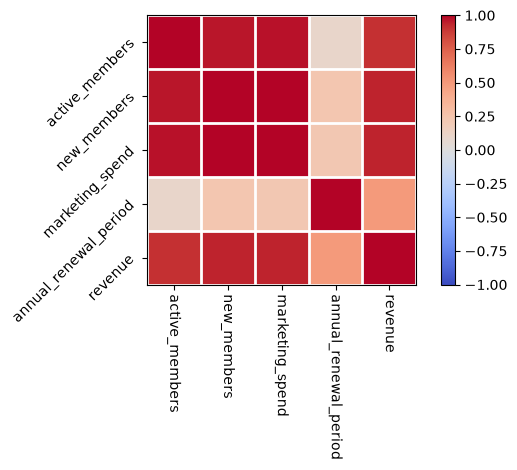

(24, 1)
         active_members  new_members  marketing_spend  annual_renewal_period  \
month                                                                          
2025-01             182           14            18000                      0   
2025-02             188           16            19000                      0   
2025-03             195           18            21000                      0   
2025-04             201           17            22000                      0   
2025-05             207           19            23000                      1   
2025-06             214           20            24000                      0   
2025-07             219           18            22000                      0   
2025-08             225           21            25000                      0   
2025-09             231           22            26000                      0   
2025-10             237           20            24000                      0   
2025-11             244         

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


monthly_revenue = pd.read_csv("../datasets/pranax_gym_monthly_revenue_synthetic.csv")
monthly_revenue = monthly_revenue.set_index(monthly_revenue.columns[0])
corr_matrix = monthly_revenue.corr()

plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=-90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45)

# Add white borders between every box
ax = plt.gca()
n = len(corr_matrix.columns)
ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)

plt.colorbar()

plt.tight_layout()
plt.show()


x = monthly_revenue.iloc[0:, :4]
y = monthly_revenue.iloc[0:, [4]]
print(y.shape)

print(monthly_revenue)

print(corr_matrix)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_Train, X_Test, Y_Train, Y_Test = train_test_split(x, y, test_size=0.25, shuffle=False)

model = LinearRegression()

model.fit(X_Train, Y_Train)
prediction = model.predict(X_Test)
prediction_dataframe = pd.DataFrame(prediction, columns=["predicted_revenue"])
signed_error = Y_Test["revenue"].to_numpy() - prediction.flatten()

MAE = np.abs(signed_error).mean()
MSE = (signed_error**2).mean()
RMSE = MSE**0.5


baseline_prediction = Y_Train["revenue"].mean()

baseline_predictions = np.full(shape=len(Y_Test), fill_value=baseline_prediction)

baseline_error = Y_Test["revenue"].to_numpy() - baseline_predictions

baseline_mae = np.abs(baseline_error).mean()
baseline_mse = (baseline_error**2).mean()
baseline_rmse = np.sqrt(baseline_mse)

print(Y_Test["revenue"].shape)
print(prediction_dataframe["predicted_revenue"].shape)
print(signed_error)
print(MAE)
print(MSE)
print(RMSE)


print("Baselines")
print(baseline_mae, baseline_mse, baseline_rmse)

(6,)
(6,)
[  799.22171907  2282.20474957  4060.50735589  5724.76868964
 13905.72970005  7853.7146382 ]
5771.024475401636
51693010.42022595
7189.785144232472
Baselines
108555.55555555555 13506864197.53086 116219.03543538322
